In [24]:
import hypernetx as hnx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import warnings 
warnings.simplefilter('ignore')
import hypernetx as hnx
import random
import matplotlib.pyplot as plt
import itertools
import math
from collections import defaultdict
import xgi

In [25]:
def generate_tripartite_3uniform(n1, n2, n3, p):
    A = list(range(n1))
    B = list(range(n1, n1 + n2))
    C = list(range(n1 + n2, n1 + n2 + n3))

    E = []

    for a in A:
        for b in B:
            for c in C:
                if random.random() < p:
                    E.append({a, b, c})

    V = A + B + C
    return V, E, A, B, C

In [26]:
def induced_hypergraph(E, C):

    filtered_edges = []

    for e in E:
        intersection = set(e) & C

        # keep edge if it still has at least 2 vertices
        # (or at least 1, depending on what you want)
        if len(intersection) >= 2:
            filtered_edges.append(list(intersection))

    print(filtered_edges)
    return hnx.Hypergraph(filtered_edges)

def draw_container(E, C, iteration):
    H_t = induced_hypergraph(E, C)
    if len(H_t.edges) == 0:
        print(f"Iteration {iteration}: Empty hypergraph (no edges left)")
        return
    plt.figure(figsize=(6,6))
    hnx.draw(H_t)
    plt.title(f"Iteration {iteration}, |C|={len(C)}")
    plt.show()

In [27]:
# Random q-uniform hypergraph using xgi
def generate_random_hypergraph_xgi(n, q, p):
    H = xgi.uniform_erdos_renyi_hypergraph(
        n,
        q,
        p,
        p_type="prob"
    )
    V = list(H.nodes)
    E = [set(e) for e in H.edges.members()]
    return V, E

In [74]:
# Greedy independent set
def greedy_independent_set(V, E):
    I = set()

    for v in V:
        conflict = False
        for e in E:
            if v in e and e.issubset(I | {v}):
                conflict = True
                break
        if not conflict:
            I.add(v)

    return I


# Degree computation (for Algorithm 1)
def compute_degrees(container, edges):
    deg = defaultdict(int)

    for e in edges:
        if e.issubset(container):
            for v in e:
                deg[v] += 1

    return deg


# Algorithm 1 (nested loops)
def algorithm1_history(V, E, I, q, rho):
    C = set(V)
    F = []
    n = len(V)
    t = 0
    container_history = []

    print("Fingerprint Algo 1: ")
    while len(C) > rho * n and I & C:
        container_history.append(C.copy())
        t += 1

        D_vertices = C.copy()
        D_edges = [e.copy() for e in E if e.issubset(C)]

        X_sets = []
        fingerprint_round = []

        for ell in range(q, 1, -1):

            deg = compute_degrees(D_vertices, D_edges)
            candidates = (I - set(v for block in F for v in block)) & D_vertices

            if not candidates:
                break

            v = max(candidates, key=lambda x: deg[x])
            fingerprint_round.append(v)

            X_ell = {w for w in D_vertices if deg[w] > deg[v]}
            X_sets.append(X_ell)

            # shrink edges containing v
            D_edges = [e - {v} for e in D_edges if v in e]
            D_vertices.remove(v)

        F.append(fingerprint_round)
        print(fingerprint_round)

        # Update container
        for X in X_sets:
            C -= X

        C -= set(fingerprint_round)

        # remove 1-edges
        one_edges = {next(iter(e)) for e in D_edges if len(e) == 1}
        C -= one_edges

    container_history.append(C.copy())
    return container_history

In [75]:
# Normalized degree for Algorithm 2
def normalized_degrees(F, C, E, n, q):
    deg = defaultdict(int)
    
    for e in E:
        if e.issubset(C | F):
            intersection_size = len(e & F)
            weight = n ** intersection_size

            for v in e:
                if v not in F:
                    deg[v] += weight

    return deg

def algorithm2_with_history(V, E, I, q, rho):
    C = set(V)
    F = []
    F_set = set()
    n = len(V)
    t = 0

    container_history = []

    print("Fingerprint Algo 2: ")
    while len(C) > rho * n and (I & C):
        container_history.append(C.copy())
        
        t += 1
        candidates = list(I - F_set)

        deg = normalized_degrees(F_set, C, E, n, q)

        v = max(candidates, key=lambda x: deg.get(x, 0))
        v_deg = deg.get(v, 0)

        # Remove higher normalized degree vertices
        remove_high = {w for w in C if deg.get(w, 0) > v_deg}
        C -= remove_high

        F.append(v)
        F_set.add(v)
        print(v)
        C.discard(v)

        # Remove singleton neighbors
        remove_singletons = set()
        for e in E:
            if len(e & F_set) == q - 1:
                remaining = next(iter(e - F_set))
                if remaining in C:
                    remove_singletons.add(remaining)

        C -= remove_singletons

    container_history.append(C.copy())
    return container_history

Independent set: 
{0, 1, 3, 4}
Fingerprint Algo 1: 
[4, 1]
[0, 3]
Fingerprint Algo 2: 
4
1
0
3
[[0, 1, 2], [0, 2, 3], [0, 3, 6], [0, 4, 6], [0, 5, 6], [1, 2, 4], [1, 2, 6], [1, 4, 5], [1, 4, 6], [2, 5, 6], [3, 4, 5], [3, 4, 6], [3, 5, 6]]


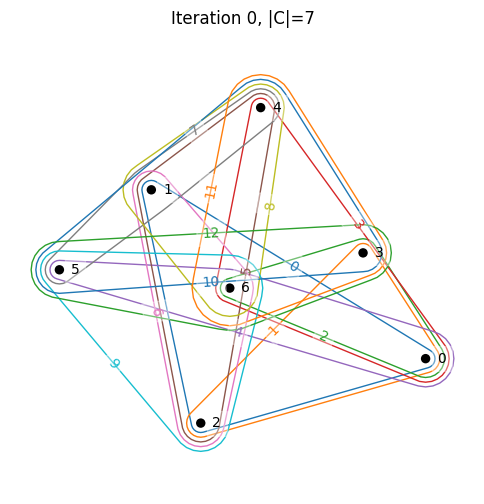

[[0, 3], [0, 3]]


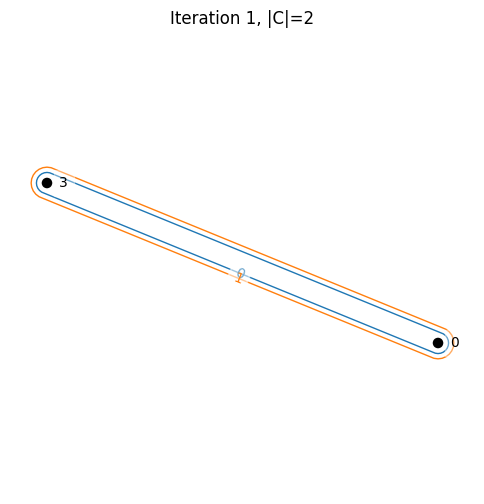

[]
Iteration 2: Empty hypergraph (no edges left)
[[0, 1, 2], [0, 2, 3], [0, 3, 6], [0, 4, 6], [0, 5, 6], [1, 2, 4], [1, 2, 6], [1, 4, 5], [1, 4, 6], [2, 5, 6], [3, 4, 5], [3, 4, 6], [3, 5, 6]]


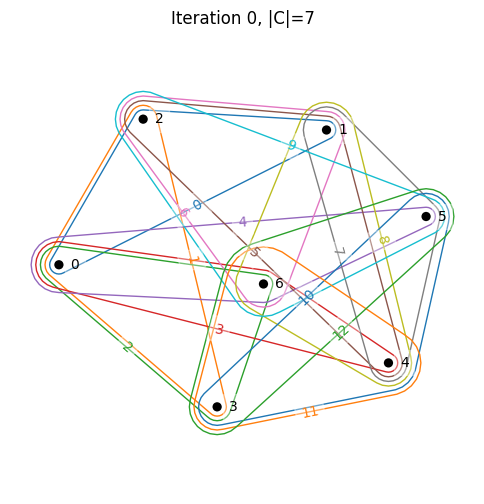

[[0, 1, 2], [0, 2, 3], [0, 3], [0, 5], [1, 2], [1, 2], [1, 5], [2, 5], [3, 5], [3, 5]]


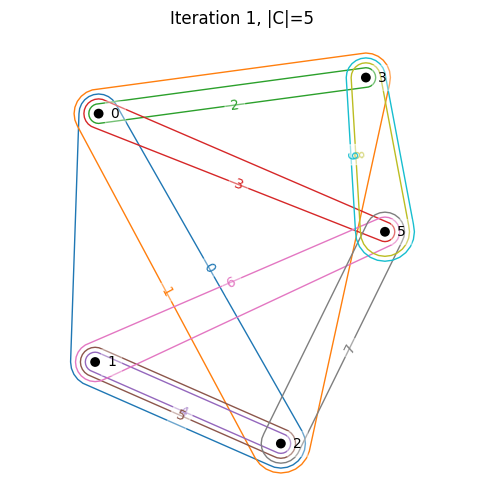

[[0, 3], [0, 3]]


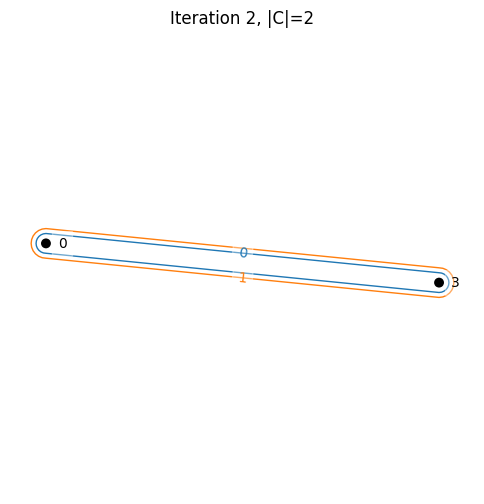

[]
Iteration 3: Empty hypergraph (no edges left)
[]
Iteration 4: Empty hypergraph (no edges left)


In [76]:
if __name__ == "__main__":
    n = 7
    q = 3
    p = 0.5
    rho = 0.01
    V, E = generate_random_hypergraph_xgi(n, q, p)
    I = greedy_independent_set(V, E) 
    print("Independent set: ")
    print(I)
    
    container_history1 = algorithm1_history(V, E, I, q, rho)
    container_history = algorithm2_with_history(V, E, I, q, rho)

    for t, C in enumerate(container_history1):
        draw_container(E, C, t)

    for t, C in enumerate(container_history):
        draw_container(E, C, t)

[[0, 3, 6], [0, 3, 7], [0, 8, 3], [0, 4, 7], [0, 8, 4], [0, 5, 6], [0, 8, 5], [1, 3, 6], [8, 1, 3], [8, 1, 4], [1, 5, 6], [8, 1, 5], [2, 3, 6], [2, 3, 7], [8, 2, 3], [2, 5, 6]]


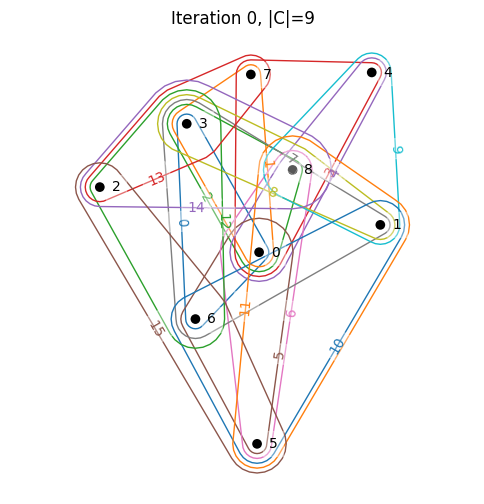

[[1, 4], [1, 5], [1, 5], [2, 5]]


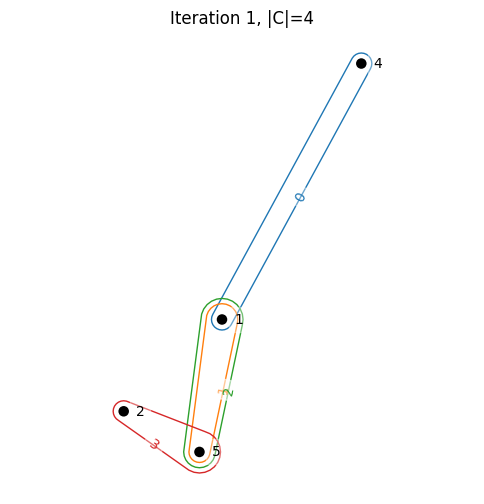

[]
Iteration 2: Empty hypergraph (no edges left)
[]
Iteration 3: Empty hypergraph (no edges left)
[[0, 3, 6], [0, 3, 7], [0, 8, 3], [0, 4, 7], [0, 8, 4], [0, 5, 6], [0, 8, 5], [1, 3, 6], [8, 1, 3], [8, 1, 4], [1, 5, 6], [8, 1, 5], [2, 3, 6], [2, 3, 7], [8, 2, 3], [2, 5, 6]]


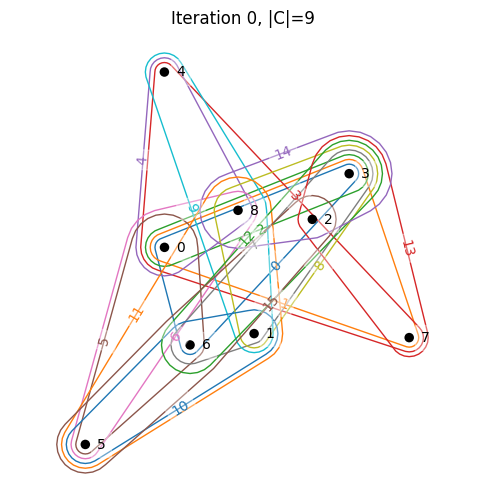

[[0, 6], [0, 7], [0, 8], [0, 4, 7], [0, 8, 4], [0, 5, 6], [0, 8, 5], [1, 6], [8, 1], [8, 1, 4], [1, 5, 6], [8, 1, 5], [2, 6], [2, 7], [8, 2], [2, 5, 6]]


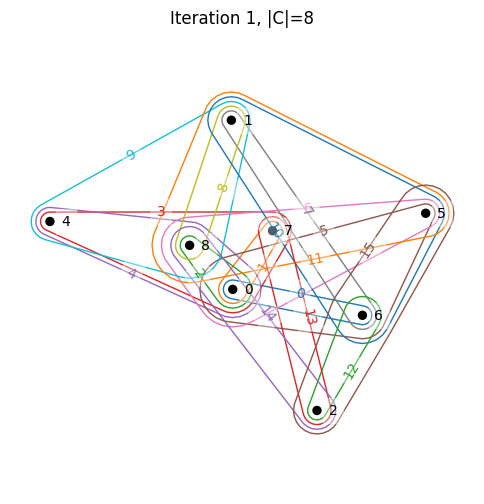

[[1, 4], [1, 5], [1, 5], [2, 5]]


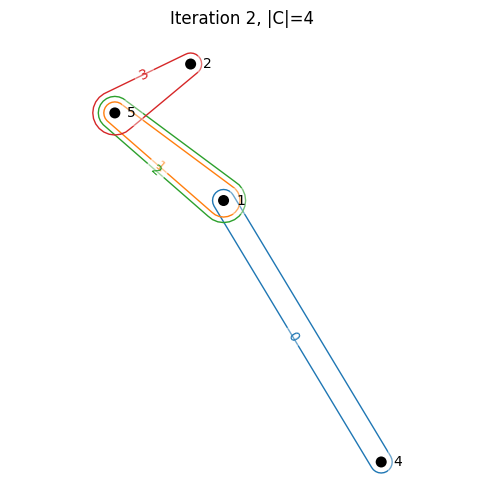

[[2, 5]]


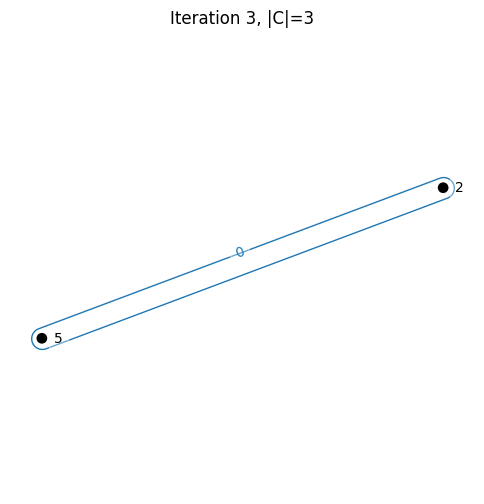

[]
Iteration 4: Empty hypergraph (no edges left)
[]
Iteration 5: Empty hypergraph (no edges left)
[]
Iteration 6: Empty hypergraph (no edges left)


In [67]:
if __name__ == "__main__":
    n1 = n2 = n3 = 3
    q = 3
    p = 0.5
    rho = 0.01
    V, E, A, B, C = generate_tripartite_3uniform(n1, n2, n3, p)
    I = greedy_independent_set(V, E) 
    
    container_history1 = algorithm1_history(V, E, I, q, rho)
    container_history = algorithm2_with_history(V, E, I, q, rho)

    for t, C in enumerate(container_history1):
        draw_container(E, C, t)

    for t, C in enumerate(container_history):
        draw_container(E, C, t)